# Caculating Probability (3PL)

`# 1 3PL Model Overview


The **3-Parameter Logistic (3PL) model** gives the probability that a person with ability $\theta$ answers a question correctly:

$$P(\text{correct} \mid \theta) = c + (1 - c) \cdot \frac{1}{1 + e^{-a(\theta - b)}}$$

Where:  

- $a$ = **Discrimination**: measures how well the item differentiates between abilities.  
- $b$ = **Difficulty**: the ability level at which the probability of a correct response is 0.5 (ignoring guessing).  
- $c$ = **Guessing**: the probability of guessing the item correctly.  
- $\theta$ = person's **ability**.

---

## 1.2 Who is Predicted First: $\theta$ or $(a, b, c)$?

- Typically, **item parameters** $a, b, c$ are estimated **first** from historical test data (a response matrix of students × items).  
- Once item parameters are known, a new student's ability $\theta$ is estimated based on their responses.  
- **Key point:** $\theta$ is **not needed** to estimate $a, b, c$; it is only estimated **after** item parameters are determined.

---

## 1.3 Estimating $\theta$ for a Student

Once the item parameters $a, b, c$ are known:

1. Collect the student's responses $R = \{ r_1, r_2, \dots, r_n \}$, where $r_i = 1$ if correct, $0$ if incorrect.  
2. Construct the **likelihood function**:

$$L(\theta \mid R) = \prod_{i=1}^{n} P_i(\text{correct} \mid \theta)^{r_i} \cdot (1 - P_i(\text{correct} \mid \theta))^{1 - r_i}$$

3. Estimate $\theta$ using either:  
   - **Maximum Likelihood Estimation (MLE):** find $\theta$ that maximizes $L(\theta \mid R)$.  
   - **Bayesian Methods:** combine a prior distribution $P(\theta)$ with the likelihood to obtain a posterior $P(\theta \mid R)$:

$$P(\theta \mid R) \propto L(\theta \mid R) \cdot P(\theta)$$

4. This process is typically performed **iteratively** until convergence.

---



# 2 3PL Formula Explained

## 2.1. **The 3PL formula**

For a given item $i$ and person $j$:

$$P(\text{correct}_{ij} \mid \theta_j) = c_i + (1 - c_i) \frac{1}{1 + e^{-a_i (\theta_j - b_i)}}$$

Where:
- $a_i$ = discrimination → how sharply the item distinguishes between abilities.
- $b_i$ = difficulty → ability level where the probability is "midpoint" (ignoring guessing).
- $c_i$ = guessing → lower asymptote (minimum probability of guessing correctly).
- $\theta_j$ = person's ability.

---

## 2.2 **How the formula works**

### **Without guessing ($c = 0$)**, the probability is just a logistic function:

$$P(\text{correct}) = \frac{1}{1 + e^{-a (\theta - b)}}$$

- When $\theta = b$, the exponent = 0 → probability = 0.5 (midpoint).
- If $\theta > b$, the probability → approaches 1.
- If $\theta < b$, probability → approaches 0.

So $b$ shifts the curve left/right (difficulty), $a$ changes the steepness (discrimination).

### **With guessing ($c > 0$)**, the curve's bottom is lifted:

- Even if $\theta$ is very low, there's still a $c$ chance of getting it right.
- The logistic part is scaled to $(1 - c)$ to ensure it doesn't exceed 1.

---

## 2.3 **Interpretation**

- **Given $\theta$ and item parameters**, the formula **directly gives the probability** that this person answers correctly.
- For adaptive testing:
  - You compute this probability for all items in the bank.
  - You select the next item that maximizes information (most useful for refining $\theta$).

---


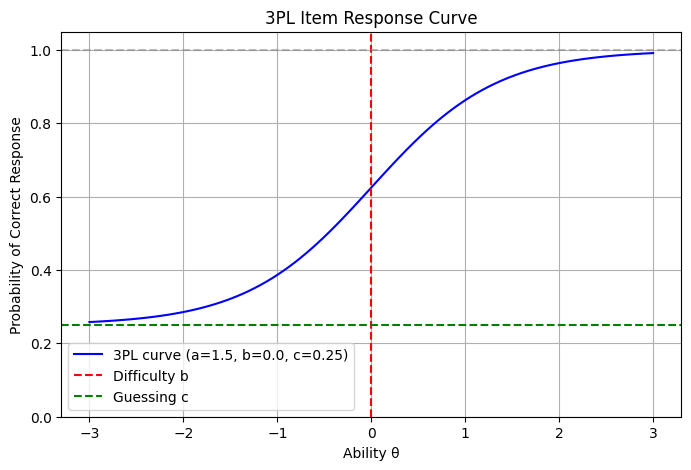

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Item parameters for 3PL
a = 1.5  # discrimination
b = 0.0  # difficulty
c = 0.25  # guessing

# Ability values
theta = np.linspace(-3, 3, 100)

# 3PL probability formula
P_correct = c + (1 - c) / (1 + np.exp(-a * (theta - b)))

# Plotting
plt.figure(figsize=(8,5))
plt.plot(theta, P_correct, label=f'3PL curve (a={a}, b={b}, c={c})', color='blue')
plt.axvline(x=b, color='red', linestyle='--', label='Difficulty b')
plt.axhline(y=c, color='green', linestyle='--', label='Guessing c')
plt.axhline(y=1, color='gray', linestyle='--', alpha=0.5)

plt.title("3PL Item Response Curve")
plt.xlabel("Ability θ")
plt.ylabel("Probability of Correct Response")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()



---

## 5. **The 3PL Curve**

Here's how to visualize the 3PL curve:

- **X-axis ($\theta$)** → student ability
- **Y-axis** → probability of getting the item correct
- **Red dashed line** → item difficulty $b$ ($\theta$ where probability ≈ 0.5 ignoring guessing)
- **Green dashed line** → guessing probability $c$ (minimum probability)

You can see:
- When $\theta \ll b$, probability ≈ $c$ (just guessing).
- When $\theta \gg b$, probability → 1 (almost certain correct).
- The steepness around $b$ is controlled by $a$ (discrimination).

This is exactly how the model predicts a student's chance of answering a question right for any $\theta$.





---

### 3. **Likelihood in Item Response Theory (IRT)**

---

In IRT, for a student with ability $\theta$, the probability of correctly answering an item is given by the **3PL model**:

$$
P(\text{correct} \mid \theta) \;=\; c + (1-c)\frac{1}{1+e^{-a(\theta - b)}}
$$

* $a$: discrimination parameter
* $b$: difficulty parameter
* $c$: guessing parameter (lower bound)

For a single response $r \in \{0,1\}$:

$$
\Pr(r \mid \theta, a, b, c) =
\begin{cases} 
P(\theta) & \text{if } r = 1 \\
1 - P(\theta) & \text{if } r = 0
\end{cases}
$$

For multiple students’ responses, the likelihood is the product:

$$
L(a,b,c \mid \text{responses}, \theta) = \prod_i P(\theta_i)^{r_i} \, (1 - P(\theta_i))^{1-r_i}
$$

---

### 3.2 **Why log-likelihood?**



---



---

# 1. Single Response Case
When a student answers one question, We have a response variable:

$$
r \in \{0,1\}
$$

* $r = 1$: student answered **correctly**
* $r = 0$: student answered **incorrectly**

The probability of a correct response for a student with ability $\theta$ is defined by the **3PL function**:

$$
P(\theta; a, b, c) = c + (1-c)\frac{1}{1 + e^{-a(\theta - b)}}
$$

where:

* $a$ = discrimination parameter (slope, how sharply the curve rises)
* $b$ = difficulty parameter (ability level at 50% success beyond guessing)
* $c$ = guessing parameter (lower bound, chance of success at very low ability)

---

Now, given one response $r$:

$$
\Pr(r \mid \theta, a, b, c) =
\begin{cases}
P(\theta) & \text{if } r = 1 \\
1 - P(\theta) & \text{if } r = 0
\end{cases}
$$

💡 This is equivalent to a **Bernoulli distribution**:

$$
\Pr(r \mid \theta, a, b, c) = \big(P(\theta)\big)^r \, \big(1 - P(\theta)\big)^{1-r}
$$

* If $r=1$, the formula reduces to $P(\theta)$.
* If $r=0$, the formula reduces to $1-P(\theta)$.

---

## 2. Multiple Students’ Responses

Suppose we observe responses from $n$ students, indexed by $i$, each with ability $\theta_i$.
Their responses are $r_i \in \{0,1\}$.

By assuming **independence of responses**, the likelihood is the **product** of individual probabilities:

$$
L(a, b, c \mid \text{responses}, \theta) = \prod_{i=1}^n \Pr(r_i \mid \theta_i, a, b, c)
$$

Substituting the Bernoulli form:

$$
L(a, b, c \mid \text{responses}, \theta) =
\prod_{i=1}^n \Big(P(\theta_i)\Big)^{r_i} \, \Big(1 - P(\theta_i)\Big)^{1-r_i}
$$

This is the **likelihood function**: it measures how plausible the parameters $(a, b, c)$ are, given the observed data.

---

## 3. Why This Matters

### 3.1 **Parameter Estimation**

* We want to find the values of $(a, b, c)$ that **maximize the likelihood**.
* This is the basis of **Maximum Likelihood Estimation (MLE)**.

---

### 3.2 **Why Log-Likelihood?**

Multiplying many probabilities can lead to **numerical underflow** (very small numbers).
So, we work with the **log-likelihood** instead:

$$
\ell(a,b,c) = \sum_{i=1}^n \Big[ r_i \log P(\theta_i) + (1-r_i) \log(1-P(\theta_i)) \Big]
$$

* The log makes products become sums.
* This form is easier to optimize computationally.
* It is exactly the **log-likelihood of a Bernoulli distribution**.

---

# Summary

* For a **single response**, use $P(\theta)$ if correct, and $1-P(\theta)$ if incorrect.
* For **multiple responses**, multiply the probabilities (likelihood).
* To estimate $(a, b, c)$, maximize the **log-likelihood**.

---


---

### 3.3 **Why negative log-likelihood (NLL)?**


* **Optimization algorithms (like `scipy.optimize.minimize`) are built to minimize functions**, not maximize them.
* Since we want to **maximize likelihood** (best parameters make data most probable), we instead minimize the **negative log-likelihood**:

$$
\text{NLL} = -\log L
$$

So the code’s `return -np.sum(ll)` is exactly that.

---

### 3.4 **What’s happening in the code**


* For each response $r_i$, it calculates the probability under the current item parameters $(a,b,c)$.
* If the student got it right, contributes $\log(p)$. If wrong, contributes $\log(1-p)$.
* Adds everything across students.
* Negates it so that smaller values = better fit (for minimization).

---

We compute **negative log-likelihood** because:

1. Likelihood represents how probable our observed responses are, given parameters.
2. Maximizing it gives the best parameters.
3. Since optimizers minimize, we negate it.

---



# Selecting initial values in ThreePLModel
Why those particular **initial values** for $(a, b, c)$ are being chosen when fitting the 3PL model by maximum likelihood. 

---


When we estimate item parameters $(a, b, c)$ with MLE or numerical optimization, the optimizer (e.g. `scipy.optimize.minimize`) needs a **starting guess**.

* A *good* starting point speeds convergence and avoids bad local minima.
* A *bad* starting point may cause divergence or convergence to nonsense values.

That’s why we make these heuristic initial guesses.

---

### Breaking down the code

```python
p_correct = np.mean(responses)
```

* This is the **observed proportion correct** for that item.
* If 70% of students got the item right, then $p_{\text{correct}} = 0.7$.
* This gives us a **rough idea of item difficulty**.

---

```python
init_b = -np.log((1 - p_correct) / p_correct) if p_correct > 0 and p_correct < 1 else 0.0
```

* Here, we’re mapping the observed proportion correct to an initial guess for the **difficulty parameter** $b$.
* Recall the **2PL logistic model** (ignoring guessing):

$$
P(\text{correct} \mid \theta) = \frac{1}{1 + e^{-(\theta - b)}}
$$

* At $\theta = 0$, this simplifies to:

$$
P(\text{correct} \mid \theta = 0) = \frac{1}{1 + e^{b}}
$$

* Solving for $b$:

$$
b = -\ln\left(\frac{1 - p}{p}\right)
$$

where $p = p_{\text{correct}}$.
So if most students got the question right, $b$ will be low (easy item). If few got it right, $b$ will be high (hard item).
That’s why the code uses that formula.

---

```python
init_params = [1.0, init_b, 0.2]
```

* $a = 1.0$: Start with **neutral discrimination** (average slope). We don’t assume high/low discrimination before data tells us.
* $b = init_b$: Start with difficulty estimated from observed proportion correct.
* $c = 0.2$: Start with a **moderate guessing parameter** (20% chance of random correct answer). This is reasonable for multiple-choice items with \~4–5 options.

---

### Why these choices?

* **p\_correct → b**: Anchors item difficulty to observed data.
* **a = 1.0**: Safe, average slope assumption to avoid instability.
* **c = 0.2**: Realistic starting point for guessing (neither 0 nor too high).

These help the optimizer converge faster and more reliably.

---






Summary Statistics by Distribution:
             Discrimination_a                                                \
                        count      mean       std       min   25%       50%   
Distribution                                                                  
Left-Skewed              20.0  1.000000  0.000000  1.000000  1.00  1.000000   
Normal                   20.0  0.962946  0.165709  0.258929  1.00  1.000000   
Right-Skewed             20.0  0.265051  0.372241  0.010000  0.01  0.025532   

                            Difficulty_b            ...                      \
                   75%  max        count      mean  ...       75%       max   
Distribution                                        ...                       
Left-Skewed   1.000000  1.0         20.0  0.372087  ...  0.457871  0.575364   
Normal        1.000000  1.0         20.0  0.512400  ...  0.489548  2.726208   
Right-Skewed  0.532487  1.0         20.0  1.958264  ...  3.000000  3.000000   

             G

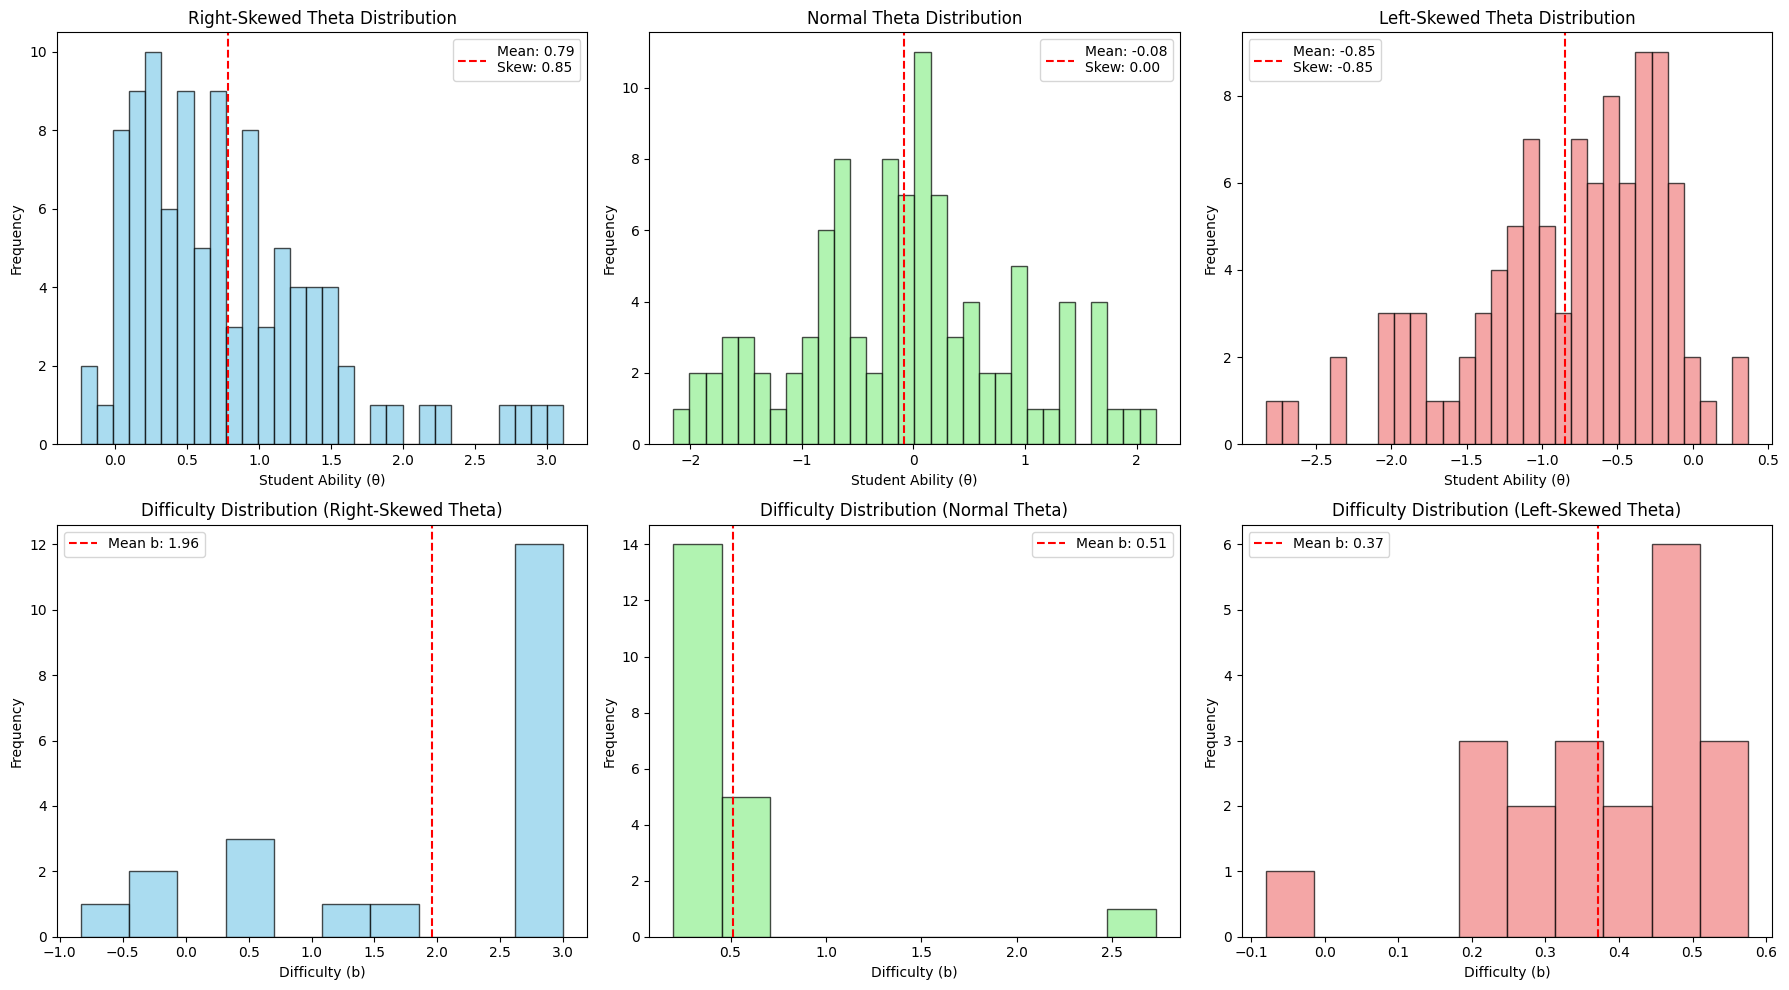

/var/folders/y0/gqnwmd7j4j76t0rjlvwt9yx80000gn/T/ipykernel_52280/1775416926.py:184: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(difficulties_data, labels=['Right-Skewed', 'Normal', 'Left-Skewed'])


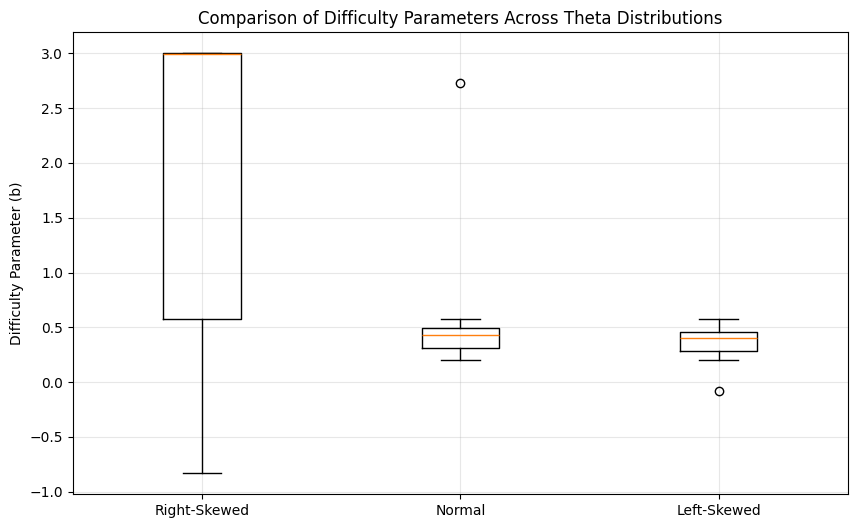

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import skewnorm
import warnings

# Suppress specific warnings if needed (optional)
warnings.filterwarnings('ignore', category=RuntimeWarning, module='scipy.optimize._numdiff')

# --- Define 3PL probability function ---
#The 3PL model gives the probability that a person with ability 𝜃 anwers the question correctly.

def three_pl(theta, a, b, c):
    """3PL model probability of correct response."""
    return c + (1 - c) / (1 + np.exp(-a * (theta - b)))

# --- Negative log-likelihood for one item ---
def nll_item(params, responses, thetas):
    a, b, c = params
    # enforce constraints (a > 0, 0 < c < 0.35)
    if a <= 0 or not (0 < c < 0.35):
        return np.inf
    
    # Calculate probabilities with numerical stability
    z = a * (thetas - b)
    
    # Handle extreme values to avoid overflow/underflow
    z = np.clip(z, -500, 500)  # Prevent overflow in exp
    
    p = c + (1 - c) / (1 + np.exp(-z))
    
    # Avoid log(0) with more conservative clipping
    p = np.clip(p, 1e-10, 1-1e-10)
    
    ll = responses * np.log(p) + (1 - responses) * np.log(1 - p)
    return -np.sum(ll)

# --- Fit 3PL model for different theta distributions ---
class ThreePLModel:
    def __init__(self):
        self.coef_ = None
        self.thetas_ = None
    
    def fit(self, response_matrix, thetas, max_iter=200):
        self.thetas_ = thetas
        n_students, n_items = response_matrix.shape
        
        coefs = []
        for j in range(n_items):
            responses = response_matrix[:, j]
            
            # Initial guesses (a, b, c) - better starting values
            p_correct = np.mean(responses) #probability of getting the question correct
            #odds of a failure
            init_b = -np.log((1 - p_correct) / p_correct) if p_correct > 0 and p_correct < 1 else 0.0
            init_params = [1.0, init_b, 0.2]
            
            try:
                res = minimize(
                    nll_item, init_params,
                    args=(responses, self.thetas_),
                    method="L-BFGS-B",
                    bounds=[(0.01, 5.0), (-3, 3), (0.01, 0.35)],
                    options={'maxiter': max_iter, 'disp': False}
                )
                
                if res.success:
                    coefs.append(res.x)
                else:
                    print(f"Warning: Optimization failed for item {j+1}, using initial values")
                    coefs.append(init_params)
                    
            except Exception as e:
                print(f"Error optimizing item {j+1}: {e}")
                coefs.append(init_params)
        
        self.coef_ = np.array(coefs)
        return self

# --- Example usage ---
if __name__ == "__main__":
    # Example: 100 students × 20 questions (binary responses 0/1)
    np.random.seed(42)
    n_students = 100
    n_items = 20
    item_response_matrix = np.random.binomial(1, 0.6, size=(n_students, n_items))
    question_ids = [f"Q{i+1}" for i in range(n_items)]

    # Create three different theta distributions
    thetas_right_skewed = skewnorm.rvs(a=5, loc=0, scale=1, size=n_students)
    thetas_normal = np.random.normal(0, 1, n_students)
    thetas_left_skewed = skewnorm.rvs(a=-5, loc=0, scale=1, size=n_students)
    
    # Fit models for each theta distribution
    model_right = ThreePLModel()
    model_right.fit(item_response_matrix, thetas_right_skewed)
    
    model_normal = ThreePLModel()
    model_normal.fit(item_response_matrix, thetas_normal)
    
    model_left = ThreePLModel()
    model_left.fit(item_response_matrix, thetas_left_skewed)
    
    # Extract parameters
    def get_params_df(model, distribution_name):
        return pd.DataFrame({
            'Item': question_ids,
            'Distribution': distribution_name,
            'Discrimination_a': model.coef_[:, 0],
            'Difficulty_b': model.coef_[:, 1],
            'Guessing_c': model.coef_[:, 2]
        })
    
    results_right = get_params_df(model_right, 'Right-Skewed')
    results_normal = get_params_df(model_normal, 'Normal')
    results_left = get_params_df(model_left, 'Left-Skewed')
    
    # Combine all results
    all_results = pd.concat([results_right, results_normal, results_left], ignore_index=True)
    print("Summary Statistics by Distribution:")
    print(all_results.groupby('Distribution')[['Discrimination_a', 'Difficulty_b', 'Guessing_c']].describe())
    
    # --- Create 2x3 subplot layout for comparison ---
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # First row: Theta distributions
    axes[0, 0].hist(thetas_right_skewed, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
    axes[0, 0].axvline(np.mean(thetas_right_skewed), color='red', linestyle='--', 
                      label=f'Mean: {np.mean(thetas_right_skewed):.2f}\nSkew: {skewnorm.stats(a=5, moments="s"):.2f}')
    axes[0, 0].set_xlabel('Student Ability (θ)')
    axes[0, 0].set_ylabel('Frequency')
    axes[0, 0].set_title('Right-Skewed Theta Distribution')
    axes[0, 0].legend()
    
    axes[0, 1].hist(thetas_normal, bins=30, edgecolor='black', alpha=0.7, color='lightgreen')
    axes[0, 1].axvline(np.mean(thetas_normal), color='red', linestyle='--', 
                      label=f'Mean: {np.mean(thetas_normal):.2f}\nSkew: {0:.2f}')
    axes[0, 1].set_xlabel('Student Ability (θ)')
    axes[0, 1].set_ylabel('Frequency')
    axes[0, 1].set_title('Normal Theta Distribution')
    axes[0, 1].legend()
    
    axes[0, 2].hist(thetas_left_skewed, bins=30, edgecolor='black', alpha=0.7, color='lightcoral')
    axes[0, 2].axvline(np.mean(thetas_left_skewed), color='red', linestyle='--', 
                      label=f'Mean: {np.mean(thetas_left_skewed):.2f}\nSkew: {skewnorm.stats(a=-5, moments="s"):.2f}')
    axes[0, 2].set_xlabel('Student Ability (θ)')
    axes[0, 2].set_ylabel('Frequency')
    axes[0, 2].set_title('Left-Skewed Theta Distribution')
    axes[0, 2].legend()
    
    # Second row: Difficulty parameter distributions
    axes[1, 0].hist(model_right.coef_[:, 1], bins=10, edgecolor='black', alpha=0.7, color='skyblue')
    axes[1, 0].axvline(np.mean(model_right.coef_[:, 1]), color='red', linestyle='--', 
                      label=f'Mean b: {np.mean(model_right.coef_[:, 1]):.2f}')
    axes[1, 0].set_xlabel('Difficulty (b)')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].set_title('Difficulty Distribution (Right-Skewed Theta)')
    axes[1, 0].legend()
    
    axes[1, 1].hist(model_normal.coef_[:, 1], bins=10, edgecolor='black', alpha=0.7, color='lightgreen')
    axes[1, 1].axvline(np.mean(model_normal.coef_[:, 1]), color='red', linestyle='--', 
                      label=f'Mean b: {np.mean(model_normal.coef_[:, 1]):.2f}')
    axes[1, 1].set_xlabel('Difficulty (b)')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].set_title('Difficulty Distribution (Normal Theta)')
    axes[1, 1].legend()
    
    axes[1, 2].hist(model_left.coef_[:, 1], bins=10, edgecolor='black', alpha=0.7, color='lightcoral')
    axes[1, 2].axvline(np.mean(model_left.coef_[:, 1]), color='red', linestyle='--', 
                      label=f'Mean b: {np.mean(model_left.coef_[:, 1]):.2f}')
    axes[1, 2].set_xlabel('Difficulty (b)')
    axes[1, 2].set_ylabel('Frequency')
    axes[1, 2].set_title('Difficulty Distribution (Left-Skewed Theta)')
    axes[1, 2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # --- Additional comparison: Boxplot of difficulties across distributions ---
    plt.figure(figsize=(10, 6))
    difficulties_data = [
        model_right.coef_[:, 1],
        model_normal.coef_[:, 1],
        model_left.coef_[:, 1]
    ]
    plt.boxplot(difficulties_data, labels=['Right-Skewed', 'Normal', 'Left-Skewed'])
    plt.ylabel('Difficulty Parameter (b)')
    plt.title('Comparison of Difficulty Parameters Across Theta Distributions')
    plt.grid(True, alpha=0.3)
    plt.show()

/var/folders/y0/gqnwmd7j4j76t0rjlvwt9yx80000gn/T/ipykernel_52280/3349065724.py:88: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax5.boxplot(boxplot_data, labels=['Right-Skewed', 'Normal', 'Left-Skewed'],


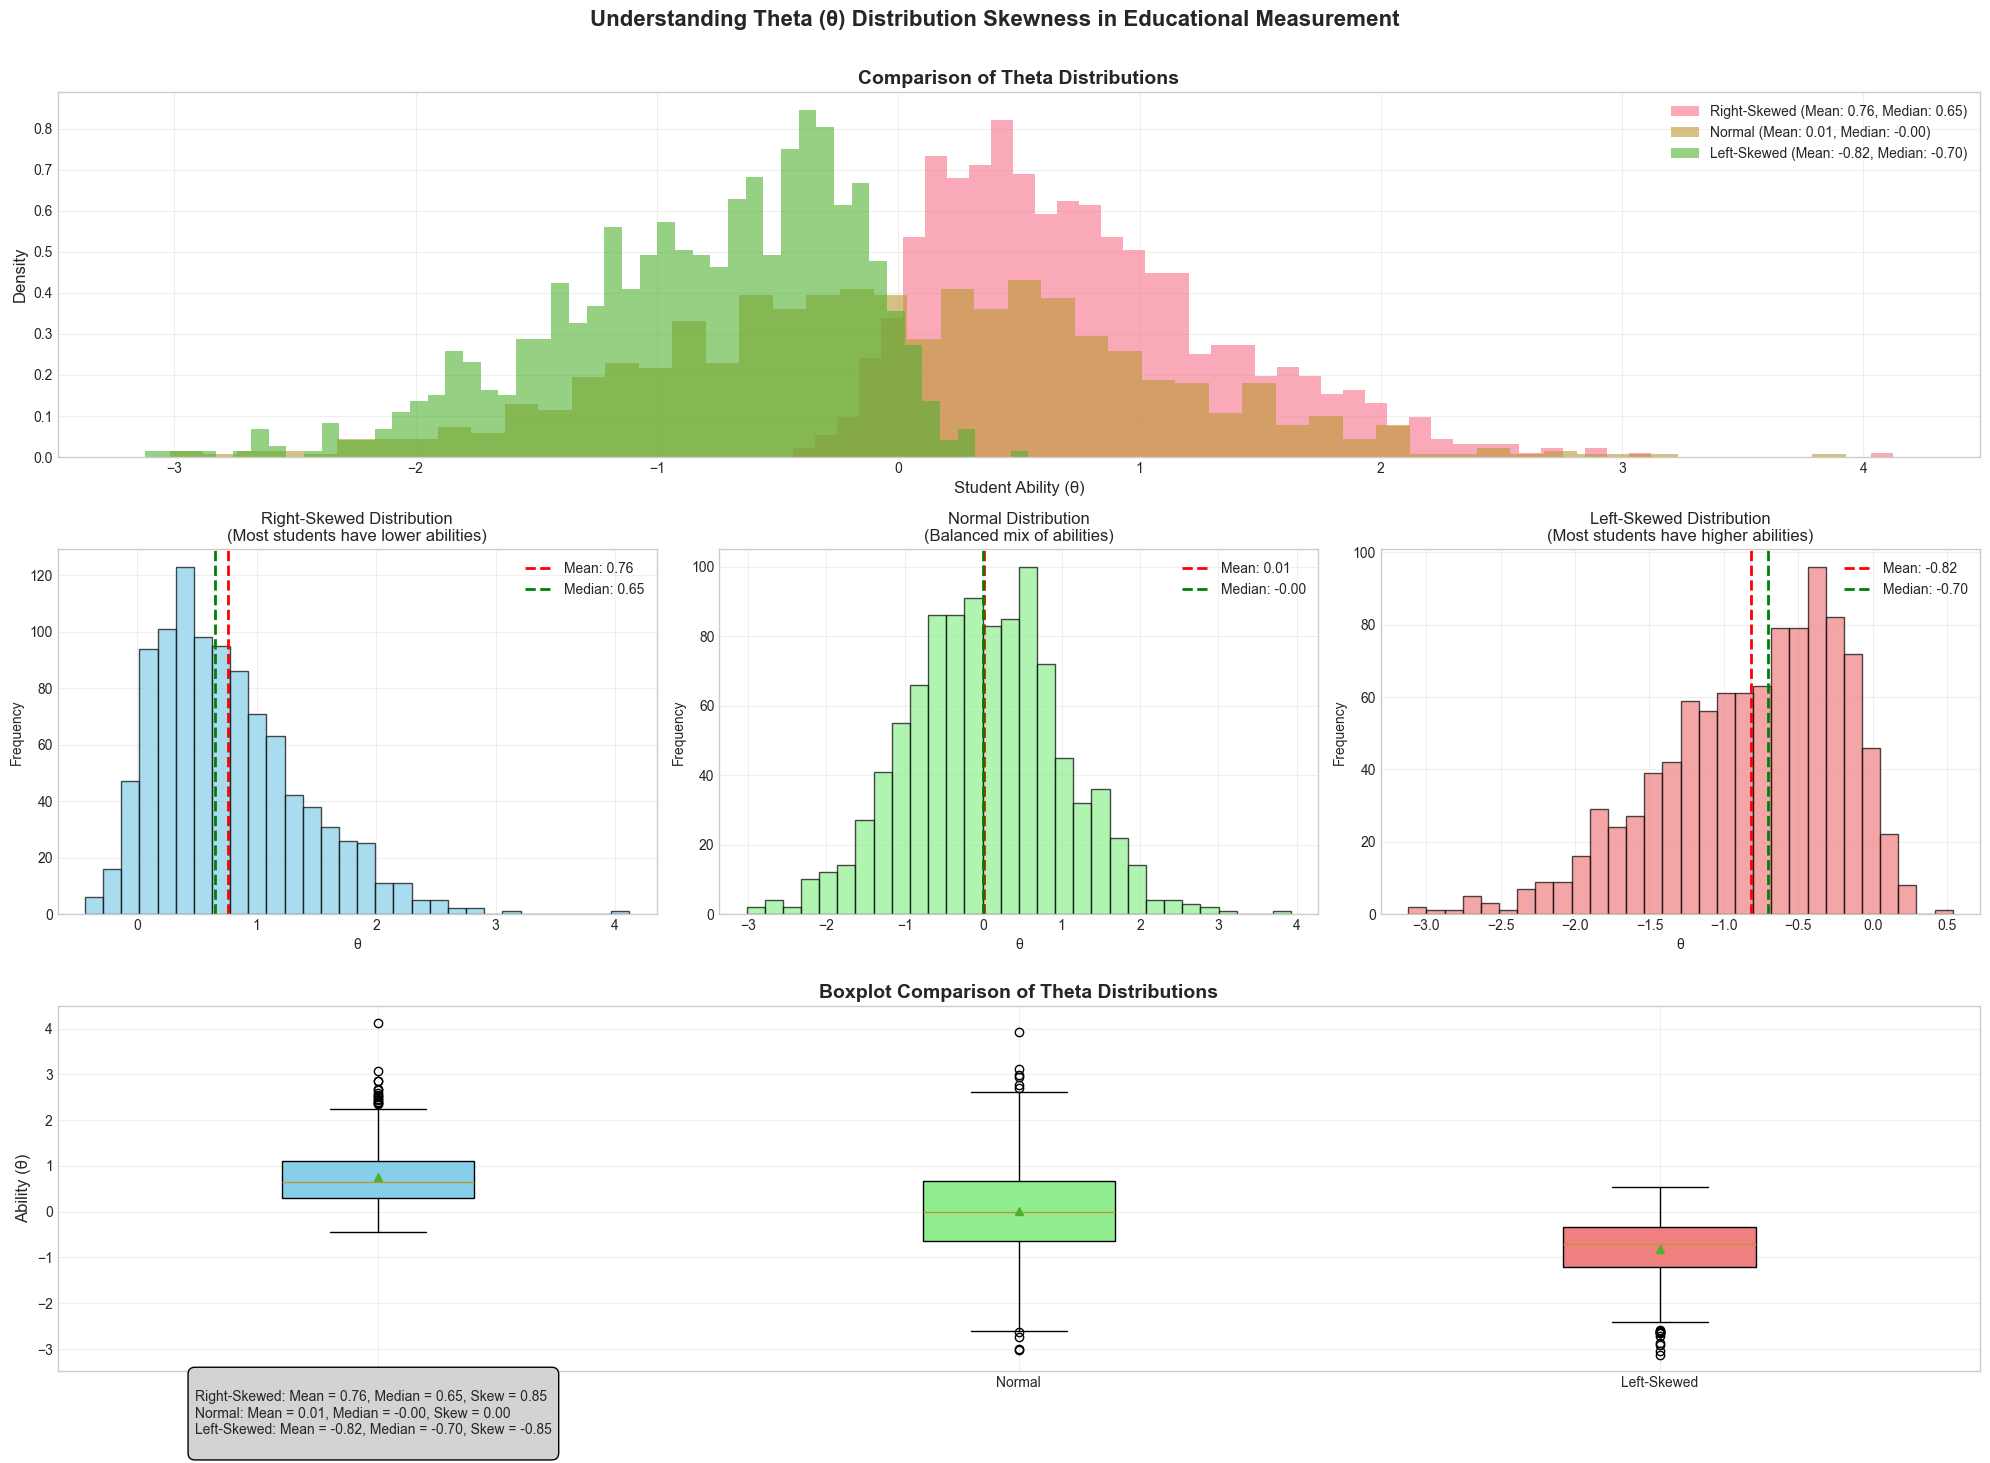

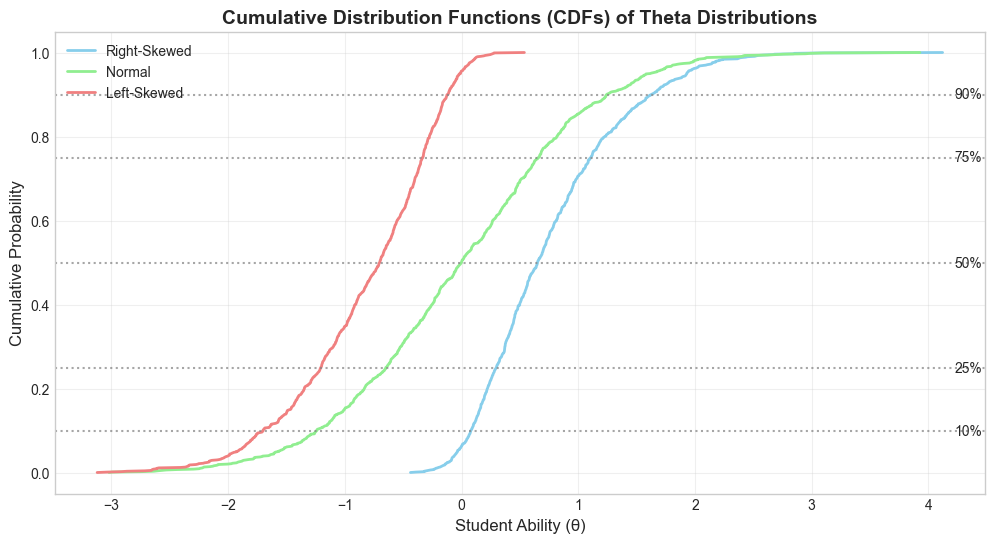

DETAILED STATISTICS OF THETA DISTRIBUTIONS

Right-Skewed Distribution:
  Mean: 0.757
  Median: 0.651
  Standard Deviation: 0.610
  Theoretical Skewness: 0.851
  Range: [-0.437, 4.121]
  Mean-Median Difference: 0.106
  Interpretation: Most students have lower abilities (struggling class)

Normal Distribution:
  Mean: 0.006
  Median: -0.000
  Standard Deviation: 0.983
  Theoretical Skewness: 0.000
  Range: [-3.020, 3.926]
  Mean-Median Difference: 0.006
  Interpretation: Balanced mix of abilities (typical class)

Left-Skewed Distribution:
  Mean: -0.817
  Median: -0.702
  Standard Deviation: 0.614
  Theoretical Skewness: -0.851
  Range: [-3.121, 0.539]
  Mean-Median Difference: -0.115
  Interpretation: Most students have higher abilities (advanced class)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skewnorm, norm
import seaborn as sns

# Set style for better visuals
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Generate the three theta distributions
np.random.seed(42)
n_students = 1000  # Larger sample for smoother distributions

# Create the three distributions
thetas_right_skewed = skewnorm.rvs(a=5, loc=0, scale=1, size=n_students)
thetas_normal = np.random.normal(0, 1, n_students)
thetas_left_skewed = skewnorm.rvs(a=-5, loc=0, scale=1, size=n_students)

# Calculate statistics for each distribution
def calculate_stats(data, name):
    return {
        'name': name,
        'mean': np.mean(data),
        'median': np.median(data),
        'std': np.std(data),
        'skewness': skewnorm.stats(a=5 if 'Right' in name else -5 if 'Left' in name else 0, moments='s'),
        'min': np.min(data),
        'max': np.max(data)
    }

stats_right = calculate_stats(thetas_right_skewed, 'Right-Skewed')
stats_normal = calculate_stats(thetas_normal, 'Normal')
stats_left = calculate_stats(thetas_left_skewed, 'Left-Skewed')

# Create a comprehensive comparison plot
fig = plt.figure(figsize=(20, 15))

# 1. Main distribution comparison
ax1 = plt.subplot2grid((3, 3), (0, 0), colspan=3)
# Plot histograms with density
ax1.hist(thetas_right_skewed, bins=50, alpha=0.6, density=True, 
         label=f'Right-Skewed (Mean: {stats_right["mean"]:.2f}, Median: {stats_right["median"]:.2f})')
ax1.hist(thetas_normal, bins=50, alpha=0.6, density=True, 
         label=f'Normal (Mean: {stats_normal["mean"]:.2f}, Median: {stats_normal["median"]:.2f})')
ax1.hist(thetas_left_skewed, bins=50, alpha=0.6, density=True, 
         label=f'Left-Skewed (Mean: {stats_left["mean"]:.2f}, Median: {stats_left["median"]:.2f})')

ax1.set_xlabel('Student Ability (θ)', fontsize=12)
ax1.set_ylabel('Density', fontsize=12)
ax1.set_title('Comparison of Theta Distributions', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Individual distribution plots
ax2 = plt.subplot2grid((3, 3), (1, 0))
ax2.hist(thetas_right_skewed, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
ax2.axvline(stats_right['mean'], color='red', linestyle='--', linewidth=2, label=f'Mean: {stats_right["mean"]:.2f}')
ax2.axvline(stats_right['median'], color='green', linestyle='--', linewidth=2, label=f'Median: {stats_right["median"]:.2f}')
ax2.set_xlabel('θ')
ax2.set_ylabel('Frequency')
ax2.set_title('Right-Skewed Distribution\n(Most students have lower abilities)')
ax2.legend()
ax2.grid(True, alpha=0.3)

ax3 = plt.subplot2grid((3, 3), (1, 1))
ax3.hist(thetas_normal, bins=30, alpha=0.7, color='lightgreen', edgecolor='black')
ax3.axvline(stats_normal['mean'], color='red', linestyle='--', linewidth=2, label=f'Mean: {stats_normal["mean"]:.2f}')
ax3.axvline(stats_normal['median'], color='green', linestyle='--', linewidth=2, label=f'Median: {stats_normal["median"]:.2f}')
ax3.set_xlabel('θ')
ax3.set_ylabel('Frequency')
ax3.set_title('Normal Distribution\n(Balanced mix of abilities)')
ax3.legend()
ax3.grid(True, alpha=0.3)

ax4 = plt.subplot2grid((3, 3), (1, 2))
ax4.hist(thetas_left_skewed, bins=30, alpha=0.7, color='lightcoral', edgecolor='black')
ax4.axvline(stats_left['mean'], color='red', linestyle='--', linewidth=2, label=f'Mean: {stats_left["mean"]:.2f}')
ax4.axvline(stats_left['median'], color='green', linestyle='--', linewidth=2, label=f'Median: {stats_left["median"]:.2f}')
ax4.set_xlabel('θ')
ax4.set_ylabel('Frequency')
ax4.set_title('Left-Skewed Distribution\n(Most students have higher abilities)')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 3. Boxplot comparison
ax5 = plt.subplot2grid((3, 3), (2, 0), colspan=3)
boxplot_data = [thetas_right_skewed, thetas_normal, thetas_left_skewed]
box = ax5.boxplot(boxplot_data, labels=['Right-Skewed', 'Normal', 'Left-Skewed'], 
                 patch_artist=True, showmeans=True)

# Color the boxes
colors = ['skyblue', 'lightgreen', 'lightcoral']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

ax5.set_ylabel('Ability (θ)', fontsize=12)
ax5.set_title('Boxplot Comparison of Theta Distributions', fontsize=14, fontweight='bold')
ax5.grid(True, alpha=0.3)

# Add text annotations with statistics
stats_text = f"""
Right-Skewed: Mean = {stats_right['mean']:.2f}, Median = {stats_right['median']:.2f}, Skew = {stats_right['skewness']:.2f}
Normal: Mean = {stats_normal['mean']:.2f}, Median = {stats_normal['median']:.2f}, Skew = 0.00
Left-Skewed: Mean = {stats_left['mean']:.2f}, Median = {stats_left['median']:.2f}, Skew = {stats_left['skewness']:.2f}
"""
fig.text(0.1, 0.02, stats_text, fontsize=10, bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgray"))

plt.tight_layout(rect=[0, 0.05, 1, 0.95])  # Adjust for text at bottom
plt.suptitle('Understanding Theta (θ) Distribution Skewness in Educational Measurement', 
             fontsize=16, fontweight='bold', y=0.98)
plt.show()

# Additional: Cumulative Distribution Functions
plt.figure(figsize=(12, 6))

# Sort data for CDF
sorted_right = np.sort(thetas_right_skewed)
sorted_normal = np.sort(thetas_normal)
sorted_left = np.sort(thetas_left_skewed)

# Calculate CDF values
cdf_right = np.arange(1, len(sorted_right) + 1) / len(sorted_right)
cdf_normal = np.arange(1, len(sorted_normal) + 1) / len(sorted_normal)
cdf_left = np.arange(1, len(sorted_left) + 1) / len(sorted_left)

plt.plot(sorted_right, cdf_right, label='Right-Skewed', linewidth=2, color='skyblue')
plt.plot(sorted_normal, cdf_normal, label='Normal', linewidth=2, color='lightgreen')
plt.plot(sorted_left, cdf_left, label='Left-Skewed', linewidth=2, color='lightcoral')

plt.xlabel('Student Ability (θ)', fontsize=12)
plt.ylabel('Cumulative Probability', fontsize=12)
plt.title('Cumulative Distribution Functions (CDFs) of Theta Distributions', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

# Add percentile lines for interpretation
percentiles = [10, 25, 50, 75, 90]
for p in percentiles:
    plt.axhline(y=p/100, color='gray', linestyle=':', alpha=0.7)
    plt.text(sorted_right[-1] + 0.1, p/100, f'{p}%', verticalalignment='center')

plt.show()

# Print detailed statistics
print("="*60)
print("DETAILED STATISTICS OF THETA DISTRIBUTIONS")
print("="*60)

for stats in [stats_right, stats_normal, stats_left]:
    print(f"\n{stats['name']} Distribution:")
    print(f"  Mean: {stats['mean']:.3f}")
    print(f"  Median: {stats['median']:.3f}")
    print(f"  Standard Deviation: {stats['std']:.3f}")
    print(f"  Theoretical Skewness: {stats['skewness']:.3f}")
    print(f"  Range: [{stats['min']:.3f}, {stats['max']:.3f}]")
    print(f"  Mean-Median Difference: {stats['mean'] - stats['median']:.3f}")
    
    # Educational interpretation
    if stats['name'] == 'Right-Skewed':
        print("  Interpretation: Most students have lower abilities (struggling class)")
    elif stats['name'] == 'Normal':
        print("  Interpretation: Balanced mix of abilities (typical class)")
    else:
        print("  Interpretation: Most students have higher abilities (advanced class)")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import skewnorm
import warnings

# Suppress specific warnings if needed (optional)
warnings.filterwarnings('ignore', category=RuntimeWarning, module='scipy.optimize._numdiff')

# --- Define 3PL probability function ---
def three_pl(theta, a, b, c):
    """3PL model probability of correct response."""
    return c + (1 - c) / (1 + np.exp(-a * (theta - b)))

# --- Negative log-likelihood for one item ---
def nll_item(params, responses, thetas):
    a, b, c = params
    # enforce constraints (a > 0, 0 < c < 0.35)
    if a <= 0 or not (0 < c < 0.35):
        return np.inf
    
    # Calculate probabilities with numerical stability
    z = a * (thetas - b)
    
    # Handle extreme values to avoid overflow/underflow
    z = np.clip(z, -500, 500)  # Prevent overflow in exp
    
    p = c + (1 - c) / (1 + np.exp(-z))
    
    # Avoid log(0) with more conservative clipping
    p = np.clip(p, 1e-10, 1-1e-10)
    
    ll = responses * np.log(p) + (1 - responses) * np.log(1 - p)
    return -np.sum(ll)

# --- Fit 3PL model for different theta distributions ---
class ThreePLModel:
    def __init__(self):
        self.coef_ = None
        self.thetas_ = None
    
    def fit(self, response_matrix, thetas, max_iter=200):
        self.thetas_ = thetas
        n_students, n_items = response_matrix.shape
        
        coefs = []
        for j in range(n_items):
            responses = response_matrix[:, j]
            
            # Initial guesses (a, b, c) - better starting values
            p_correct = np.mean(responses)
            init_b = -np.log((1 - p_correct) / p_correct) if p_correct > 0 and p_correct < 1 else 0.0
            init_params = [1.0, init_b, 0.2]
            
            try:
                res = minimize(
                    nll_item, init_params,
                    args=(responses, self.thetas_),
                    method="L-BFGS-B",
                    bounds=[(0.01, 5.0), (-3, 3), (0.01, 0.35)],
                    options={'maxiter': max_iter, 'disp': False}
                )
                
                if res.success:
                    coefs.append(res.x)
                else:
                    print(f"Warning: Optimization failed for item {j+1}, using initial values")
                    coefs.append(init_params)
                    
            except Exception as e:
                print(f"Error optimizing item {j+1}: {e}")
                coefs.append(init_params)
        
        self.coef_ = np.array(coefs)
        return self

# --- Example usage ---
if __name__ == "__main__":
    # Example: 100 students × 20 questions (binary responses 0/1)
    np.random.seed(42)
    n_students = 100
    n_items = 20
    item_response_matrix = np.random.binomial(1, 0.6, size=(n_students, n_items))
    question_ids = [f"Q{i+1}" for i in range(n_items)]

    # Create three different theta distributions
    thetas_right_skewed = skewnorm.rvs(a=5, loc=0, scale=1, size=n_students)
    thetas_normal = np.random.normal(0, 1, n_students)
    thetas_left_skewed = skewnorm.rvs(a=-5, loc=0, scale=1, size=n_students)
    
    # Fit models for each theta distribution
    model_right = ThreePLModel()
    model_right.fit(item_response_matrix, thetas_right_skewed)
    
    model_normal = ThreePLModel()
    model_normal.fit(item_response_matrix, thetas_normal)
    
    model_left = ThreePLModel()
    model_left.fit(item_response_matrix, thetas_left_skewed)
    
    # Extract parameters
    def get_params_df(model, distribution_name):
        return pd.DataFrame({
            'Item': question_ids,
            'Distribution': distribution_name,
            'Discrimination_a': model.coef_[:, 0],
            'Difficulty_b': model.coef_[:, 1],
            'Guessing_c': model.coef_[:, 2]
        })
    
    results_right = get_params_df(model_right, 'Right-Skewed')
    results_normal = get_params_df(model_normal, 'Normal')
    results_left = get_params_df(model_left, 'Left-Skewed')
    
    # Combine all results
    all_results = pd.concat([results_right, results_normal, results_left], ignore_index=True)
    print("Summary Statistics by Distribution:")
    print(all_results.groupby('Distribution')[['Discrimination_a', 'Difficulty_b', 'Guessing_c']].describe())
    
    # --- Create 2x3 subplot layout for comparison ---
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # First row: Theta distributions
    axes[0, 0].hist(thetas_right_skewed, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
    axes[0, 0].axvline(np.mean(thetas_right_skewed), color='red', linestyle='--', 
                      label=f'Mean: {np.mean(thetas_right_skewed):.2f}\nSkew: {skewnorm.stats(a=5, moments="s"):.2f}')
    axes[0, 0].set_xlabel('Student Ability (θ)')
    axes[0, 0].set_ylabel('Frequency')
    axes[0, 0].set_title('Right-Skewed Theta Distribution')
    axes[0, 0].legend()
    
    axes[0, 1].hist(thetas_normal, bins=30, edgecolor='black', alpha=0.7, color='lightgreen')
    axes[0, 1].axvline(np.mean(thetas_normal), color='red', linestyle='--', 
                      label=f'Mean: {np.mean(thetas_normal):.2f}\nSkew: {0:.2f}')
    axes[0, 1].set_xlabel('Student Ability (θ)')
    axes[0, 1].set_ylabel('Frequency')
    axes[0, 1].set_title('Normal Theta Distribution')
    axes[0, 1].legend()
    
    axes[0, 2].hist(thetas_left_skewed, bins=30, edgecolor='black', alpha=0.7, color='lightcoral')
    axes[0, 2].axvline(np.mean(thetas_left_skewed), color='red', linestyle='--', 
                      label=f'Mean: {np.mean(thetas_left_skewed):.2f}\nSkew: {skewnorm.stats(a=-5, moments="s"):.2f}')
    axes[0, 2].set_xlabel('Student Ability (θ)')
    axes[0, 2].set_ylabel('Frequency')
    axes[0, 2].set_title('Left-Skewed Theta Distribution')
    axes[0, 2].legend()
    
    # Second row: Difficulty parameter distributions
    axes[1, 0].hist(model_right.coef_[:, 1], bins=10, edgecolor='black', alpha=0.7, color='skyblue')
    axes[1, 0].axvline(np.mean(model_right.coef_[:, 1]), color='red', linestyle='--', 
                      label=f'Mean b: {np.mean(model_right.coef_[:, 1]):.2f}')
    axes[1, 0].set_xlabel('Difficulty (b)')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].set_title('Difficulty Distribution (Right-Skewed Theta)')
    axes[1, 0].legend()
    
    axes[1, 1].hist(model_normal.coef_[:, 1], bins=10, edgecolor='black', alpha=0.7, color='lightgreen')
    axes[1, 1].axvline(np.mean(model_normal.coef_[:, 1]), color='red', linestyle='--', 
                      label=f'Mean b: {np.mean(model_normal.coef_[:, 1]):.2f}')
    axes[1, 1].set_xlabel('Difficulty (b)')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].set_title('Difficulty Distribution (Normal Theta)')
    axes[1, 1].legend()
    
    axes[1, 2].hist(model_left.coef_[:, 1], bins=10, edgecolor='black', alpha=0.7, color='lightcoral')
    axes[1, 2].axvline(np.mean(model_left.coef_[:, 1]), color='red', linestyle='--', 
                      label=f'Mean b: {np.mean(model_left.coef_[:, 1]):.2f}')
    axes[1, 2].set_xlabel('Difficulty (b)')
    axes[1, 2].set_ylabel('Frequency')
    axes[1, 2].set_title('Difficulty Distribution (Left-Skewed Theta)')
    axes[1, 2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # --- Additional comparison: Boxplot of difficulties across distributions ---
    plt.figure(figsize=(10, 6))
    difficulties_data = [
        model_right.coef_[:, 1],
        model_normal.coef_[:, 1],
        model_left.coef_[:, 1]
    ]
    plt.boxplot(difficulties_data, labels=['Right-Skewed', 'Normal', 'Left-Skewed'])
    plt.ylabel('Difficulty Parameter (b)')
    plt.title('Comparison of Difficulty Parameters Across Theta Distributions')
    plt.grid(True, alpha=0.3)
    plt.show()